In [1]:
import numpy as np

# Load the camera calibration
data = np.load('../calibration/IMX219_stereo.npz')
mtx_left = data['mtx_left']
dist_left = data['dist_left']
mtx_right = data['mtx_right']
dist_right = data['dist_right']

R = data['R']
T = data['T']

width = 1920
height = 1080

In [2]:
import cv2

rectify_scale = 1  # Should be 0 if size is the same, 1 if not
R1, R2, P1, P2, _, _, _ = cv2.stereoRectify(
    mtx_left, dist_left,
    mtx_right, dist_right,
    (width, height), R, T,
    rectify_scale, (0, 0)
)

left_map1, left_map2 = cv2.initUndistortRectifyMap(
    mtx_left, dist_left, R1, P1, (width, height), 5
)
right_map1, right_map2 = cv2.initUndistortRectifyMap(
    mtx_right, dist_right, R2, P2, (width, height), 5
)

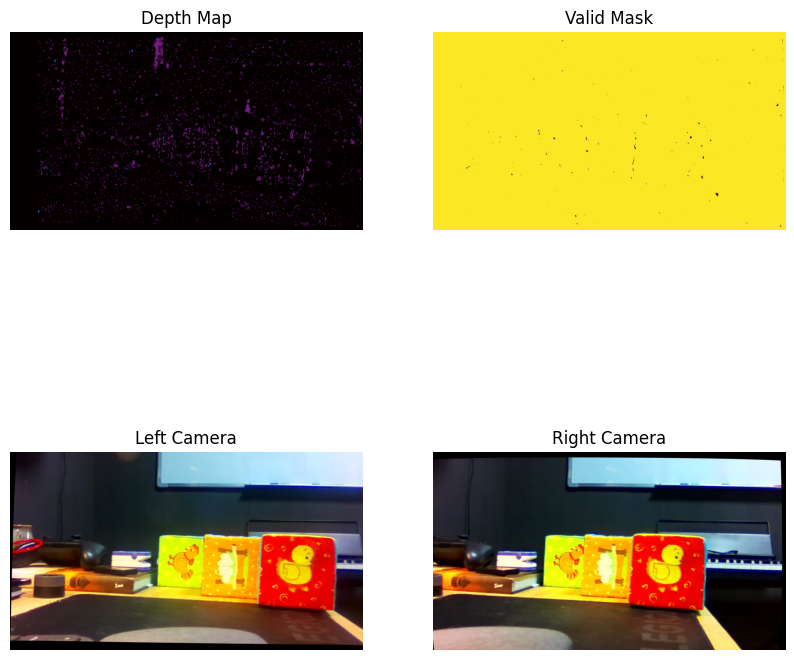

In [3]:
from IPython.display import clear_output
import matplotlib.pyplot as plt
from picamera2 import Picamera2

# Camera IDs for left and right cameras
LEFT_CAMERA_ID = 1  
RIGHT_CAMERA_ID = 0

# Setup cameras
picam_left = Picamera2(LEFT_CAMERA_ID)
picam_right = Picamera2(RIGHT_CAMERA_ID)
for cam in [picam_left, picam_right]:
    cam.preview_configuration.main.size = (width, height)
    cam.preview_configuration.main.format = "YUV420"
    cam.configure("preview")
    cam.start()

prev_gray_left = None
while True:
    try:
        # Capture frames from both cameras
        frame_left = picam_left.capture_array()
        frame_right = picam_right.capture_array()

        # Convert YUV420 to RGB
        frame_left = cv2.cvtColor(frame_left, cv2.COLOR_YUV2RGB_I420)
        frame_right = cv2.cvtColor(frame_right, cv2.COLOR_YUV2RGB_I420)
        
        # Rectify the images
        rectified_left = cv2.remap(frame_left, left_map1, left_map2, cv2.INTER_LINEAR)
        rectified_right = cv2.remap(frame_right, right_map1, right_map2, cv2.INTER_LINEAR)

        # Convert frames to grayscale
        gray_left = cv2.cvtColor(rectified_left, cv2.COLOR_RGB2GRAY)
        gray_right = cv2.cvtColor(rectified_right, cv2.COLOR_RGB2GRAY)
        gray_left = np.uint8(gray_left)
        gray_right = np.uint8(gray_right)

        # Filter
        kernel = np.ones((3,3), np.float32)/9
        filtered_left = cv2.filter2D(gray_left, -1, kernel)
        filtered_right = cv2.filter2D(gray_right, -1, kernel)

        # Calculate disparity map and depth map
        stereo = cv2.StereoBM.create(numDisparities=16*9, blockSize=15)
        disparity = stereo.compute(filtered_left, filtered_right).astype(np.float32)    
        valid_mask = disparity != 0
        depth_map = np.zeros_like(disparity)
        focal_length = mtx_left[0, 0]
        baseline = abs(np.linalg.norm(T))
        depth_map[valid_mask] = (focal_length * baseline) / disparity[valid_mask]

        clear_output(wait=True)

        plt.figure(figsize=(10, 10))
        plt.subplots_adjust(hspace=0.2)

        # Display depth map and cameras 
        plt.subplot(2, 2, 1)
        plt.axis('off') 
        plt.title('Depth Map')
        normalized_depth = cv2.normalize(depth_map, None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)
        colored_depth = cv2.applyColorMap(normalized_depth, cv2.COLORMAP_INFERNO)
        plt.imshow(colored_depth)

        plt.subplot(2, 2, 2)
        plt.axis('off') 
        plt.title('Valid Mask')
        plt.imshow(valid_mask)

        plt.subplot(2, 2, 3)
        plt.axis('off') 
        plt.title('Left Camera')
        plt.imshow(rectified_left)

        plt.subplot(2, 2, 4)
        plt.axis('off') 
        plt.title('Right Camera')
        plt.imshow(rectified_right)

        plt.show()
        
        # Split depth_map into zones 256x256 pixels and calculate mean of each
        # zone_size = 256
        # h, w = depth_map.shape
        # n_zones_h = h // zone_size 
        # n_zones_w = w // zone_size
        
        # zone_means = np.zeros((n_zones_h, n_zones_w))
        # for i in range(n_zones_h):
        #     for j in range(n_zones_w):
        #         zone = depth_map[i*zone_size:(i+1)*zone_size, j*zone_size:(j+1)*zone_size]
        #         zone_means[i,j] = np.nanmean(zone)  # Only consider valid depth values
        # print(zone_means)

    except KeyboardInterrupt:
        break

picam_left.close()
picam_right.close()

In [6]:
picam_left.close()
picam_right.close()


In [18]:
colored_depth = cv2.applyColorMap(normalized_depth, cv2.COLORMAP_BONE)